# Buildfest: Understanding 988 Training Survey, Data Cleaning

**Goal of the project:** figure out whether the Understanding 988 training is reaching its target audiences and whether it works equally well across communities (younger people, communities of color, Spanish speakers, parents, school staff), and find the **gaps**.

**Key message the training is supposed to land:** you do not have to be in a crisis to call 988. You can call, text, or chat on a bad day, or call for someone else. It is free and confidential.

This notebook has two parts:

| Part | What it does | Status |
|---|---|---|
| **Part 1: Basic cleaning** | Renames columns, fixes formatting problems, standardizes answers, flags bad rows, exports a clean file | Done, ready to use |
| **Part 2: Exploration + advanced cleaning ideas** | First look at gaps across groups, plus a list of proposed new columns and groupings | For team review before we commit to it |
| **Part 3: Deeper insights** | Five angles the standard averages hide, each tied to a decision EveryMind can make | Draft findings |
| **Part 4: Outside data** | EveryMind's own 988 figures and Census county data, to answer "compared to what?" and "who is missing?" | Draft findings |

Every code cell has a short explanation above it saying what the command does and why.

## 0. Setup

`pandas` is the main table library. `numpy` is for numeric helpers. `re` is Python's regular-expression module, used for text matching. `matplotlib` is for the few charts in Part 2.

`pd.set_option(...)` just makes the notebook show more columns and longer text when we print tables.

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

RAW_PATH = "data/buildfest_raw.xlsx"      # copy of "Kevin's Buildfest_data_cleaned(2).xlsx"
OUT_DIR = "output"

---
# Part 1: Basic Cleaning

## 1.1 Load the data

The Excel file has two sheets:
* `Uncleaned Survey Data`: the full export, **1,299 rows**.
* `Survey Data Cleaned`: the earlier manual cleaning, only **135 rows**.

We start from the **uncleaned** sheet so every step is reproducible in code. `pd.ExcelFile(...).sheet_names` lists the sheets; `pd.read_excel(..., sheet_name=...)` reads one into a DataFrame (a table).

In [ ]:
print(pd.ExcelFile(RAW_PATH).sheet_names)

raw = pd.read_excel(RAW_PATH, sheet_name="Uncleaned Survey Data")
prev_clean = pd.read_excel(RAW_PATH, sheet_name="Survey Data Cleaned")

print("raw shape:", raw.shape, "| earlier cleaned sheet shape:", prev_clean.shape)

['Survey Data Cleaned', 'Uncleaned Survey Data']


raw shape: (1299, 22) | earlier cleaned sheet shape: (135, 20)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


`.head()` shows the first rows. `.T` flips (transposes) the table so each column becomes a row, which is easier to read when the column names are long survey questions.

In [ ]:
raw.head(3).T

,0,1,2
Power Query,NaN,2.0,3.0
Please enter the date of your training.,2025-10-21,NaN,2025-10-21
Time taken,00:01:50,00:01:59,00:02:14
Date taken,2025-10-21,2025-10-21,2025-10-21
Start time,2025-10-21 14:08:09,2025-10-21 14:08:07,2025-10-21 14:08:08
TRIM(,2025-10-21 14:09:59,2025-10-21 14:10:06,2025-10-21 14:10:22
Language,English (United States)‎,English (United States)‎,English (United States)‎
Are you a....?,School staff member;,School staff member;,School staff member;
Which county is this training affiliated with?,Anne Arundel,Anne Arundel,Anne Arundel
Please tell us how much you disagree or agree with the statements..I can identify mental health challenges and crises.,Strongly agree,Strongly agree,Strongly agree


## 1.2 Quick health check of the raw data

For each column we print:
* `dtype`: what type pandas thinks the column is (text, number, ...).
* `non_null`: how many rows actually have an answer (`.notna().sum()`).
* `pct_missing`: percent of rows that are blank.
* `n_unique`: number of distinct answers (`.nunique()`).

This is the fastest way to spot problem columns.

In [ ]:
health = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "pct_missing": (raw.isna().mean() * 100).round(1),
    "n_unique": raw.nunique(),
})
health

,dtype,non_null,pct_missing,n_unique
Power Query,float64,1298,0.1,1298
Please enter the date of your training.,str,1295,0.3,46
Time taken,str,1299,0.0,263
Date taken,str,1299,0.0,53
Start time,str,1299,0.0,1293
TRIM(,str,1299,0.0,1299
Language,str,1299,0.0,2
Are you a....?,str,1299,0.0,17
Which county is this training affiliated with?,str,1299,0.0,15
Please tell us how much you disagree or agree with the statements..I can identify mental health challenges and crises.,str,1299,0.0,5


**What this shows:**
* Two columns have broken names from the Excel Power Query step: `Power Query` is really a row ID, and `TRIM(` is really the **completion time** (it is always a little after `Start time`).
* The last question, *"How likely are you to call 988..."*, is blank for **~77%** of rows. This turns out to be the reason the earlier cleaning shrank to 135 rows (see section 1.11).
* The three "aspects of the training" questions are blank for ~12% of rows.

## 1.3 Rename the columns

The original column names are the full survey questions, which are long and contain hidden characters (non-breaking spaces, `\xa0`). We give every column a short `snake_case` name.

We also keep a **codebook** (`codebook` table) that maps each new name back to the exact original question, so nothing is lost. The codebook is exported with the data.

Naming pattern for the 3 knowledge questions, asked twice:
* `post_...` = "Please tell us how much you agree..." (how they feel **now, after** training)
* `pre_...` = "Now think back to **before** you took part..." (a *retrospective pre-test*)

In [ ]:
new_names = [
    "row_id",            # was 'Power Query'
    "training_date",
    "time_taken",
    "date_taken",
    "start_time",
    "completion_time",   # was 'TRIM(' (broken name)
    "language",
    "role_raw",
    "county_raw",
    "post_identify",     # I CAN identify mental health challenges and crises
    "post_describe",     # I CAN describe 988 and how it works
    "post_when_use",     # I KNOW when to use 988
    "pre_identify",      # BEFORE: I could identify ...
    "pre_describe",      # BEFORE: I could describe 988 ...
    "pre_when_use",      # BEFORE: I knew when to use 988
    "presenter_engaged",
    "presenter_knew",
    "well_organized",
    "recommend_0_10",
    "likely_call_0_10",
    "most_valuable_text",
    "improve_text",
]

codebook = pd.DataFrame({
    "new_name": new_names,
    "original_question": [re.sub(r"\s+", " ", str(c).replace("\xa0", " ")).strip() for c in raw.columns],
})

df = raw.copy()            # always work on a copy so `raw` stays untouched
df.columns = new_names
codebook

,new_name,original_question
0,row_id,Power Query
1,training_date,Please enter the date of your training.
2,time_taken,Time taken
3,date_taken,Date taken
4,start_time,Start time
5,completion_time,TRIM(
6,language,Language
7,role_raw,Are you a....?
8,county_raw,Which county is this training affiliated with?
9,post_identify,Please tell us how much you disagree or agree with the statements..I can ide...


## 1.4 Strip hidden whitespace from every text cell

Several answers contain invisible characters:
* `"Strongly agree\xa0"` (a non-breaking space at the end) is treated as a **different answer** from `"Strongly agree"`.
* `"English (United States)‎"` has a hidden left-to-right mark.
* `"Fairfax "` vs `"Fairfax"` (trailing space).

The helper below replaces those characters with normal spaces, collapses double spaces, and trims the ends. `df[col].map(fn)` runs the function on every cell of a column. We only touch text (`object`/`string`) columns.

In [ ]:
HIDDEN = {"\xa0": " ", "‎": "", "‏": "", "​": "", "﻿": ""}

def clean_text(x):
    '''Return x with hidden unicode removed, spaces collapsed, ends trimmed.
    Non-strings (NaN, numbers) are returned unchanged.
    Usage: df["col"].map(clean_text)'''
    if not isinstance(x, str):
        return x
    for bad, good in HIDDEN.items():
        x = x.replace(bad, good)
    x = re.sub(r"\s+", " ", x).strip()
    return x if x else np.nan     # an empty string becomes a real missing value

text_cols = df.select_dtypes(include=["object", "string"]).columns
for c in text_cols:
    df[c] = df[c].map(clean_text)

print("cleaned", len(text_cols), "text columns")

cleaned 19 text columns


## 1.5 Fix the ID and convert dates / times to real types

* `row_id`: the first row has a blank ID. Since the IDs are just 1..1299 in order, we rebuild it with `range(1, n+1)` so every row has a unique ID.
* `pd.to_datetime(...)` turns text like `"2026-09-28"` into real dates so we can sort, subtract, and group by month. `errors="coerce"` turns anything unparseable into `NaT` (missing) instead of crashing.
* `pd.to_timedelta(...).dt.total_seconds()` turns `"00:01:50"` into `110` seconds, which is easier to analyze.

In [ ]:
print("blank IDs before:", df["row_id"].isna().sum())
df["row_id"] = range(1, len(df) + 1)

for c in ["training_date", "date_taken"]:
    df[c] = pd.to_datetime(df[c], errors="coerce").dt.normalize()
for c in ["start_time", "completion_time"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")

df["seconds_taken"] = pd.to_timedelta(df["time_taken"].astype(str), errors="coerce").dt.total_seconds()
df = df.drop(columns="time_taken")     # replaced by seconds_taken

df[["row_id", "training_date", "date_taken", "start_time", "completion_time", "seconds_taken"]].head()

blank IDs before: 1


,row_id,training_date,date_taken,start_time,completion_time,seconds_taken
0,1,2025-10-21,2025-10-21,2025-10-21 14:08:09,2025-10-21 14:09:59,110.0
1,2,NaT,2025-10-21,2025-10-21 14:08:07,2025-10-21 14:10:06,119.0
2,3,2025-10-21,2025-10-21,2025-10-21 14:08:08,2025-10-21 14:10:22,134.0
3,4,2025-10-21,2025-10-21,2025-10-21 14:08:00,2025-10-21 14:10:30,150.0
4,5,2025-10-21,2025-10-21,2025-10-21 14:09:38,2025-10-21 14:10:49,71.0


**Sanity check:** `completion_time - start_time` should equal `seconds_taken`. If it does, we know `completion_time` really is what we think it is (the old `TRIM(` column).

In [ ]:
gap = (df["completion_time"] - df["start_time"]).dt.total_seconds() - df["seconds_taken"]
print("rows where the times disagree by > 2 seconds:", (gap.abs() > 2).sum())

rows where the times disagree by > 2 seconds: 0


## 1.6 Standardize `language`

The survey platform records the language the form was **displayed in**. Only two values exist. We shorten them to `English` / `Spanish`. `.replace({...})` swaps values using a dictionary.

Note: this is the *form* language, not the language people actually wrote in. Section 1.10 handles Spanish answers given on the English form.

In [ ]:
df["form_language"] = df["language"].replace({
    "English (United States)": "English",
    "Español (México)": "Spanish",
})
df = df.drop(columns="language")
df["form_language"].value_counts()

form_language
English    1280
Spanish      19
Name: count, dtype: int64

## 1.7 Standardize `county`

The same county is typed many ways (`"Montgomery"`, `"Montgomery County"`, `"Montgomery County with NAMI MC"`, `"Fairfax county"`...). We:
1. lowercase the value and remove the word "county" (`str.lower()`, `re.sub`),
2. match it against a small lookup table,
3. add a `state` column and an `in_md_service_area` flag. Fairfax is in Virginia and Harris is most likely Harris County, Texas, so those rows are outside the Maryland trainings and are flagged (not deleted).

`value_counts(dropna=False)` counts each value, including blanks.

In [ ]:
print(df["county_raw"].value_counts(dropna=False), "\n")

def standardize_county(x):
    '''Map messy county text to one canonical county name.
    Usage: df["county_raw"].map(standardize_county)  ->  "Montgomery", "Prince George's", ...'''
    if not isinstance(x, str):
        return np.nan
    k = re.sub(r"\bcounty\b.*$", "", x.lower()).strip()    # drop "county" and anything after it
    lookup = {
        "anne arundel": "Anne Arundel",
        "prince george's": "Prince George's",
        "montgomery": "Montgomery",
        "queen anne's": "Queen Anne's",
        "fairfax": "Fairfax",
        "harris": "Harris",
    }
    return lookup.get(k, x)    # unknown values pass through so we notice them

df["county"] = df["county_raw"].map(standardize_county)
df["state"] = df["county"].map({"Fairfax": "VA", "Harris": "TX"}).fillna("MD")
df["in_md_service_area"] = df["state"].eq("MD")

df["county"].value_counts(dropna=False)

county_raw
Anne Arundel                      937
Prince George's                   309
Montgomery                         31
Queen Anne's County                12
Fairfax                             4
Montgomery County                   2
Fairfax county                      1
Fairfax County                      1
Montgomery County with NAMI MC      1
Harris                              1
Name: count, dtype: int64 



county
Anne Arundel       937
Prince George's    309
Montgomery          34
Queen Anne's        12
Fairfax              6
Harris               1
Name: count, dtype: int64

## 1.8 Split the multi-select "Are you a...?" question

People could pick more than one role, so values look like `"School staff member;Caregiver/parent;"`. A cell with several answers can't be grouped cleanly, so we:
* make one **True/False column per role** (`is_student`, `is_school_staff`, `is_caregiver`, `is_community_member`) using `str.contains`,
* make a single `role_primary` column: the role if they picked one, or `"Multiple roles"` if they picked several.

In [ ]:
ROLE_PATTERNS = {
    "is_student":          r"student",
    "is_school_staff":     r"school staff",
    "is_caregiver":        r"caregiver|parent",
    "is_community_member": r"other|community",
}
ROLE_LABELS = {
    "is_student": "Student",
    "is_school_staff": "School staff",
    "is_caregiver": "Caregiver/parent",
    "is_community_member": "Community member",
}

role_text = df["role_raw"].fillna("").str.lower()
for col, pattern in ROLE_PATTERNS.items():
    df[col] = role_text.str.contains(pattern, regex=True)

df["n_roles"] = df[list(ROLE_PATTERNS)].sum(axis=1)

def primary_role(row):
    '''Return the single role label, "Multiple roles", or NaN if none ticked.
    Usage: df.apply(primary_role, axis=1)'''
    picked = [ROLE_LABELS[c] for c in ROLE_PATTERNS if row[c]]
    if len(picked) == 0:
        return np.nan
    return picked[0] if len(picked) == 1 else "Multiple roles"

df["role_primary"] = df.apply(primary_role, axis=1)
df["role_primary"].value_counts(dropna=False)

role_primary
Student             1076
Community member      89
School staff          63
Caregiver/parent      57
Multiple roles        14
Name: count, dtype: int64

## 1.9 Standardize the Likert (agree/disagree) answers and convert them to numbers

Problems found in the 9 agree/disagree questions:
* `"Neither agree or disagree"` vs `"Neither agree nor disagree"` (two spellings of the same option).
* `"Very agree"` and `"Satisfied"` show up in the 3 "aspects of the training" questions. These are not options on a standard 5-point scale, so they likely come from a different version of the form. **Judgment call:** we map `Very agree` to *Strongly agree* and `Satisfied` to *Agree*, and keep a flag (`had_nonstandard_likert`) so the team can exclude them later if they disagree.

Then each label gets a number: Strongly disagree = 1 ... Strongly agree = 5. Numbers let us compute averages and pre-to-post change. We keep the text columns and add `_num` versions.

In [ ]:
LIKERT_COLS = ["post_identify", "post_describe", "post_when_use",
               "pre_identify", "pre_describe", "pre_when_use",
               "presenter_engaged", "presenter_knew", "well_organized"]

for c in LIKERT_COLS:
    print(c, df[c].value_counts(dropna=False).to_dict())

post_identify {'Agree': 619, 'Strongly agree': 549, 'Neither agree nor disagree': 78, 'Strongly disagree': 40, 'Disagree': 13}
post_describe {'Strongly agree': 662, 'Agree': 513, 'Neither agree nor disagree': 70, 'Strongly disagree': 39, 'Disagree': 15}
post_when_use {'Strongly agree': 769, 'Agree': 430, 'Neither agree nor disagree': 47, 'Strongly disagree': 41, 'Disagree': 12}
pre_identify {'Agree': 703, 'Neither agree nor disagree': 259, 'Strongly agree': 235, 'Disagree': 59, 'Strongly disagree': 43}
pre_describe {'Agree': 422, 'Neither agree nor disagree': 331, 'Disagree': 240, 'Strongly agree': 182, 'Strongly disagree': 124}
pre_when_use {'Agree': 442, 'Strongly agree': 281, 'Neither agree nor disagree': 267, 'Disagree': 182, 'Strongly disagree': 127}
presenter_engaged {'Strongly agree': 566, 'Agree': 423, nan: 151, 'Neither agree or disagree': 98, 'Strongly disagree': 24, 'Disagree': 14, 'Very agree': 13, 'Satisfied': 10}
presenter_knew {'Strongly agree': 678, 'Agree': 334, nan: 1

In [ ]:
LIKERT_FIX = {
    "Neither agree or disagree": "Neither agree nor disagree",
    "Very agree": "Strongly agree",
    "Satisfied": "Agree",
}
LIKERT_SCORE = {
    "Strongly disagree": 1,
    "Disagree": 2,
    "Neither agree nor disagree": 3,
    "Agree": 4,
    "Strongly agree": 5,
}

df["had_nonstandard_likert"] = df[LIKERT_COLS].isin(["Very agree", "Satisfied"]).any(axis=1)

for c in LIKERT_COLS:
    df[c] = df[c].replace(LIKERT_FIX)
    df[c + "_num"] = df[c].map(LIKERT_SCORE)

# every non-blank answer should now have a score; this should print 0
unmapped = sum((df[c].notna() & df[c + "_num"].isna()).sum() for c in LIKERT_COLS)
print("unmapped Likert answers:", unmapped)
print("rows with a 'Very agree'/'Satisfied' answer:", df["had_nonstandard_likert"].sum())

unmapped Likert answers: 0
rows with a 'Very agree'/'Satisfied' answer: 24


## 1.10 Check the 0 to 10 questions

`recommend_0_10` and `likely_call_0_10` should be whole numbers from 0 to 10. `.between(0, 10)` checks the range. Anything outside would be set to missing (there are none, but the check is cheap).

In [ ]:
for c in ["recommend_0_10", "likely_call_0_10"]:
    bad = df[c].notna() & ~df[c].between(0, 10)
    print(c, "| out of range:", bad.sum(), "| missing:", df[c].isna().sum())
    df.loc[bad, c] = np.nan

recommend_0_10 | out of range: 0 | missing: 33
likely_call_0_10 | out of range: 0 | missing: 1006


## 1.11 Detect Spanish answers (even when the form says English)

The `form_language` column only says which version of the form was shown. Some people on the **English** form wrote their open-ended answers in **Spanish**. That matters for the "gaps across communities" question, because Spanish speakers are one of the communities we care about.

Simple approach (no extra library needed): count common Spanish words vs. common English words in the two text answers. If there are at least 2 Spanish hits and more Spanish than English hits, or the text has Spanish-only characters (ñ, ¿, ¡), we mark the answer as Spanish.

`text_language` is `Spanish`, `English`, or `No text`. `spanish_speaker` is True if the form **or** the text is Spanish.

In [ ]:
ES_WORDS = set('''que para los las una por con del como pero muy mas más hay ayuda saber esta está
son mis nuestros nuestras hijos hija hijo familia gracias información informacion puede
personas cuando donde todo todos siempre llamar apoyo yo tengo nada bien sobre también tambien
cómo qué algo ellos entrenamiento'''.split())
EN_WORDS = set('''the and to is you that of it can how for this with are when what call about
know learned someone people was have be not if or more'''.split())

def detect_language(text):
    '''Guess if a free-text answer is Spanish or English using word counts.
    Usage: detect_language("que hay personas que pueden ayudar")  ->  "Spanish"'''
    if not isinstance(text, str) or not text.strip():
        return np.nan
    words = re.findall(r"[a-záéíóúñü]+", text.lower())
    es = sum(w in ES_WORDS for w in words)
    en = sum(w in EN_WORDS for w in words)
    if re.search(r"[ñ¿¡]", text.lower()) or (es >= 2 and es > en):
        return "Spanish"
    return "English"

both_text = df["most_valuable_text"].fillna("") + " " + df["improve_text"].fillna("")
df["text_language"] = both_text.map(detect_language).fillna("No text")
df["spanish_speaker"] = df["form_language"].eq("Spanish") | df["text_language"].eq("Spanish")

print(pd.crosstab(df["form_language"], df["text_language"], margins=True))

text_language  English  No text  Spanish   All
form_language                                 
English           1004      223       53  1280
Spanish              4        2       13    19
All               1008      225       66  1299


Look at the Spanish-text answers that were submitted on the **English** form, to confirm the detector is working (and not catching English answers):

In [ ]:
df.loc[df["form_language"].eq("English") & df["text_language"].eq("Spanish"),
       ["row_id", "county", "role_primary", "most_valuable_text", "improve_text"]]

,row_id,county,role_primary,most_valuable_text,improve_text
84,85,Prince George's,Caregiver/parent,"Que hay un recurso, para ayudar a los personas, que estan en crisis mentale","Compalindo toda los padres toda infainodia, necesaria para ayuda la diciplin..."
86,87,Prince George's,Community member,Aprendi que no solo es para los estudiantes el 988 sino tambien para adultos...,Me encanto que hubo donuts y cafe tambien los recordatorios son importantes
87,88,Prince George's,Caregiver/parent,La mas valioso que aprendi es saber del 988 porque saber que alguien puede e...,Es importante que compartimos la informacion con los otros personas y saber ...
88,89,Prince George's,Caregiver/parent,Lo que apprendi que ay un numero 988 para llamar y que nos escuchen y ayuden...,Que todas las personas sepan que ay un lugar donde llamar textos para ser es...
89,90,Prince George's,School staff,Aprendimos como ayudar a alguien.,Informandole a otros compañeros.
90,91,Prince George's,Caregiver/parent,Como podre usar ese numero y que es importante hablar.,Fue excelente.
91,92,Prince George's,Caregiver/parent,Como detectar la crisis y como usar el numero.,Estubo bien.
92,93,Prince George's,Caregiver/parent,Que si ay quien nos escuchi y nos pueden ayudar.,A poder yegar alas familia que estan pasando por este proseso.
93,94,Prince George's,Multiple roles,Conocer que hay ayuda para mi familia y amistades.,Ayudar a todas las escuelas del pais.
94,95,Prince George's,Caregiver/parent,Es muy importante tener en cuenta esta informacion. Es importante dedicar el...,Llamar al 988 de ser necesario tanto para mi o mi familia ser escuchando es ...


## 1.12 Data-quality flags

We **flag** questionable rows instead of deleting them, so the team can decide in Part 2 how strict to be. Each flag is a True/False column:

| Flag | Rule | Why |
|---|---|---|
| `flag_too_fast` | finished in under 20 seconds | ~15 questions incl. 2 text boxes can't be read in < 20s |
| `flag_straightline` | the same answer on all 6 pre/post questions **and** all 3 aspects | possible "clicked through" pattern (can also be genuine) |
| `flag_training_after_survey` | training date is after the survey date | impossible, probably a typo |
| `flag_no_training_date` | training date blank | can't link to a session |
| `flag_low_effort_text` | "most valuable" answer is empty-ish (`none`, `idk`, `n/a`, `nothing`, 1 character) | not useful for text analysis |

In [ ]:
df["flag_too_fast"] = df["seconds_taken"] < 20

df["flag_straightline"] = (
    df[LIKERT_COLS[:6]].nunique(axis=1).eq(1)
    & df[LIKERT_COLS[6:]].nunique(axis=1).eq(1)
)

df["flag_training_after_survey"] = df["training_date"] > df["date_taken"]
df["flag_no_training_date"] = df["training_date"].isna()

LOW_EFFORT = r"^(none\.?|no|nothing|n/?a|idk|i don'?t know|nope|\.|-|.)$"
df["flag_low_effort_text"] = (
    df["most_valuable_text"].isna()
    | df["most_valuable_text"].str.lower().str.fullmatch(LOW_EFFORT, na=False)
)

df["days_training_to_survey"] = (df["date_taken"] - df["training_date"]).dt.days

flag_cols = [c for c in df.columns if c.startswith("flag_")]
df[flag_cols].sum().to_frame("rows_flagged")

,rows_flagged
flag_too_fast,16
flag_straightline,119
flag_training_after_survey,1
flag_no_training_date,4
flag_low_effort_text,237


## 1.13 Why did the earlier cleaning leave only 135 rows?

The earlier version kept only rows where **every** question was answered. The problem is the `likely_call_0_10` question (column R in the cleaned sheet). It is not that people skipped it: **the question was not on the form for most of the year.** The table below groups by survey month (`dt.to_period("M")`) and shows what share of rows have that answer.

In [ ]:
by_month = (df.assign(month=df["date_taken"].dt.to_period("M"))
              .groupby("month")
              .agg(responses=("row_id", "size"),
                   pct_has_likely_call=("likely_call_0_10", lambda s: round(s.notna().mean() * 100)),
                   pct_has_aspects=("presenter_engaged", lambda s: round(s.notna().mean() * 100))))
by_month

,responses,pct_has_likely_call,pct_has_aspects
month,,,
2025-10,18,0,100
2025-11,7,0,100
2025-12,37,0,100
2026-01,21,0,100
2026-02,36,0,100
2026-03,6,0,100
2026-04,95,20,95
2026-05,400,29,97
2026-06,27,96,96


So `likely_call_0_10` was only asked on some versions of the form (mostly April to August 2026, and part of October). Requiring it throws away about 1,000 good responses. The same is true, to a smaller degree, for the 3 "aspects of training" questions.

**Decision (agreed by the team): "core + per-question" rule.** Don't require `likely_call_0_10`. Keep it as a column and add `asked_likely_call` so it is only analyzed on the rows that saw it. Instead, define **completeness tiers**:

| Column | Meaning |
|---|---|
| `complete_core` | all 6 pre/post knowledge questions answered (the heart of the "did it work?" question) |
| `complete_closed` | core **plus** the 3 aspects **plus** the recommend score |
| `complete_all` | every question incl. likely-to-call and both text boxes (this is the old 135-row rule) |

**The rule we use:**
1. A row goes into `analysis_ready` if it is `complete_core` (all 6 before/after questions answered).
2. Every other measure is computed **only on the rows that answered that question**: the 3 aspects (~1,140 rows), the recommend score (~1,250), and likely-to-call (~290, only the forms that asked it). Blanks are never treated as a low score.
3. Every group table reports the number of rows behind each measure (`n_aspects`, `n_recommend`, `n_likely_call`), so small bases are visible.

`complete_closed` and `complete_all` stay in the file as flags in case we want a fixed sample later, but they are **not** used to drop rows.

In [ ]:
PREPOST = LIKERT_COLS[:6]
ASPECTS = LIKERT_COLS[6:]

df["asked_likely_call"] = df["likely_call_0_10"].notna()
df["complete_core"] = df[PREPOST].notna().all(axis=1)
df["complete_closed"] = df["complete_core"] & df[ASPECTS + ["recommend_0_10"]].notna().all(axis=1)
df["complete_all"] = (df["complete_closed"] & df["asked_likely_call"]
                      & df[["most_valuable_text", "improve_text"]].notna().all(axis=1))

df[["complete_core", "complete_closed", "complete_all"]].sum().to_frame("rows")

,rows
complete_core,1299
complete_closed,1123
complete_all,135


`complete_all` should be close to the 135 rows of the earlier manual cleaning, which confirms we understand where that number came from.

## 1.14 Build the analysis-ready table

Rules for the main analysis file (`analysis_ready`):
* keep rows that are `complete_core` (pre/post answered),
* keep rows inside the Maryland service area,
* drop rows that are `flag_too_fast` **and** `flag_straightline` at the same time (both signals together are a strong sign of a junk response; either one alone is kept but flagged).

Everything else stays in `cleaned_all` with its flags, so nothing is lost.

Finally we put the columns in a sensible order (IDs and dates, then who the person is, then answers, then flags) using a list and `df[order]`.

In [ ]:
COL_ORDER = (
    ["row_id", "training_date", "date_taken", "days_training_to_survey", "start_time", "completion_time", "seconds_taken",
     "form_language", "text_language", "spanish_speaker",
     "county", "state", "in_md_service_area", "county_raw",
     "role_primary", "n_roles"] + list(ROLE_PATTERNS) + ["role_raw"]
    + [c for pair in zip(LIKERT_COLS, [c + "_num" for c in LIKERT_COLS]) for c in pair]
    + ["recommend_0_10", "likely_call_0_10", "asked_likely_call",
       "most_valuable_text", "improve_text"]
    + ["complete_core", "complete_closed", "complete_all", "had_nonstandard_likert"] + flag_cols
)
assert set(COL_ORDER) == set(df.columns), set(df.columns) ^ set(COL_ORDER)
cleaned_all = df[COL_ORDER].copy()

junk = cleaned_all["flag_too_fast"] & cleaned_all["flag_straightline"]
analysis_ready = cleaned_all[
    cleaned_all["complete_core"] & cleaned_all["in_md_service_area"] & ~junk
].copy()

print("cleaned_all   :", cleaned_all.shape)
print("analysis_ready:", analysis_ready.shape, f"(vs 135 in the earlier cleaning)")
print("removed as too-fast + straight-line:", junk.sum())

cleaned_all   : (1299, 53)
analysis_ready: (1289, 53) (vs 135 in the earlier cleaning)
removed as too-fast + straight-line: 3


## 1.15 Cleaning log and export

A short log of every change (counts are computed, not typed), then we write one Excel file with four sheets using `pd.ExcelWriter`:
* `analysis_ready`: the main table for analysis,
* `cleaned_all`: every row, cleaned, with flags,
* `codebook`: short column name to original question,
* `cleaning_log`: what we did.

We also save a CSV copy of `analysis_ready` for tools that prefer CSV.

In [ ]:
codebook_full = pd.DataFrame({"new_name": cleaned_all.columns}).merge(codebook, on="new_name", how="left")
codebook_full["original_question"] = codebook_full["original_question"].fillna("(derived in this notebook)")

log = pd.DataFrame([
    ("Renamed all columns to snake_case; fixed broken 'Power Query' and 'TRIM(' names", len(raw.columns)),
    ("Removed hidden characters (non-breaking spaces etc.) from text columns", len(text_cols)),
    ("Rebuilt row_id (first row had a blank ID)", 1),
    ("Standardized county spellings into 6 counties", raw.iloc[:, 8].nunique()),
    ("Flagged rows outside the MD service area (Fairfax VA, Harris TX)", int((~df["in_md_service_area"]).sum())),
    ("Split multi-select role into 4 True/False columns + role_primary", int((df["n_roles"] > 1).sum())),
    ("Merged 'Neither agree or disagree' spelling", int(raw.isin(["Neither agree or disagree"]).sum().sum())),
    ("Mapped 'Very agree' -> Strongly agree, 'Satisfied' -> Agree (flagged)", int(df["had_nonstandard_likert"].sum())),
    ("Detected Spanish text answers on the English form", int((df["form_language"].eq("English") & df["text_language"].eq("Spanish")).sum())),
    ("Flag: finished in under 20 seconds", int(df["flag_too_fast"].sum())),
    ("Flag: straight-lined all Likert questions", int(df["flag_straightline"].sum())),
    ("Flag: training date after survey date", int(df["flag_training_after_survey"].sum())),
    ("Removed: too fast AND straight-lined", int(junk.sum())),
    ("Removed: pre/post questions not all answered", int((~df["complete_core"]).sum())),
    ("Rows in analysis_ready", len(analysis_ready)),
], columns=["step", "rows_or_values_affected"])

import os
os.makedirs(OUT_DIR, exist_ok=True)
xlsx_path = f"{OUT_DIR}/buildfest_988_cleaned.xlsx"
with pd.ExcelWriter(xlsx_path) as xw:
    analysis_ready.to_excel(xw, sheet_name="analysis_ready", index=False)
    cleaned_all.to_excel(xw, sheet_name="cleaned_all", index=False)
    codebook_full.to_excel(xw, sheet_name="codebook", index=False)
    log.to_excel(xw, sheet_name="cleaning_log", index=False)
analysis_ready.to_csv(f"{OUT_DIR}/buildfest_988_analysis_ready.csv", index=False)

print("wrote", xlsx_path)
log

wrote output/buildfest_988_cleaned.xlsx


,step,rows_or_values_affected
0,Renamed all columns to snake_case; fixed broken 'Power Query' and 'TRIM(' names,22
1,Removed hidden characters (non-breaking spaces etc.) from text columns,19
2,Rebuilt row_id (first row had a blank ID),1
3,Standardized county spellings into 6 counties,15
4,"Flagged rows outside the MD service area (Fairfax VA, Harris TX)",7
5,Split multi-select role into 4 True/False columns + role_primary,14
6,Merged 'Neither agree or disagree' spelling,237
7,"Mapped 'Very agree' -> Strongly agree, 'Satisfied' -> Agree (flagged)",24
8,Detected Spanish text answers on the English form,53
9,Flag: finished in under 20 seconds,16


## 1.16 Final export: a truly clean sheet and an expanded sheet

Two sheets for two jobs:

| Sheet | Rows | Columns | Use it for |
|---|---|---|---|
| **clean** | analysis-ready rows, minus likely reversed-scale answers and duplicate submissions | only what the analysis needs (numbers, not text labels) | charts, stats, the memo |
| **expanded** | all 1,299 rows | every original column + every flag + every derived measure | auditing, checking any decision, future work |

What this step adds on top of 1.1 to 1.15:
1. **New flags**
   * `flag_reversed_scale`: all 3 "after" items are *Strongly disagree* but the person rated the training 4+ or would recommend it 7+. They most likely read the scale backwards.
   * `flag_possible_duplicate`: both comments are identical (ignoring case) to an earlier response, so it is probably the same person submitting twice.
   * `flag_late_survey`: surveyed 30+ days after training (memory fades, or the training date is wrong).
2. **Privacy:** presenter and staff names in comments are replaced with `[name]`. Names are needed nowhere in the analysis, and first-round judging is blind.
3. **Dropped columns** in the clean sheet, with the reason for each (see `DROP_REASONS`).
4. **Derived measures** (gain, averages, session ID, NPS group, key-message theme) so nobody has to recompute them.


In [ ]:
# ---------- 1. new flags (computed on every row, so they appear in the expanded sheet too) ----------
full = cleaned_all.copy()
POST_NUM = ["post_identify_num", "post_describe_num", "post_when_use_num"]
PRE_NUM = ["pre_identify_num", "pre_describe_num", "pre_when_use_num"]
ASPECT_NUM = ["presenter_engaged_num", "presenter_knew_num", "well_organized_num"]

full["aspects_avg"] = full[ASPECT_NUM].mean(axis=1)
full["flag_reversed_scale"] = (
    full[POST_NUM].notna().all(axis=1)
    & full[POST_NUM].eq(1).all(axis=1)
    & ((full["aspects_avg"] >= 4) | (full["recommend_0_10"] >= 7))
)

def comment_key(row):
    """Lowercased 'valuable || improve' text, or None if either comment is short or blank.
    Short answers like 'nothing' or 'when to call 988' repeat naturally, so only longer comments count as duplicates.
    Usage: full.apply(comment_key, axis=1)"""
    v, i = row["most_valuable_text"], row["improve_text"]
    if not (isinstance(v, str) and isinstance(i, str)) or min(len(v), len(i)) < 20:
        return None
    return v.lower().strip(" .") + " || " + i.lower().strip(" .")

keys = full.apply(comment_key, axis=1)
full["flag_possible_duplicate"] = keys.notna() & keys.duplicated(keep="first")   # first copy stays
full["flag_late_survey"] = full["days_training_to_survey"] >= 30

# ---------- 2. remove names from comments ----------
STAFF_NAMES = ["Andrea", "Jennifer", "Athena Thomas", "Athena", "Sophia"]        # found by reading the comments
TITLED_NAME = r"\b(?:Mr|Mrs|Ms|Miss|Dr|Coach)\.?\s+[A-Z][a-z'’-]+"                  # e.g. "Ms. Morales"

def redact_names(text):
    """Replace known staff first names and titled names with [name]. Non-text is returned unchanged.
    Usage: redact_names("Athena Thomas was great")  ->  "[name] was great" """
    if not isinstance(text, str):
        return text
    for n in STAFF_NAMES:
        text = re.sub(rf"\b{n}\b", "[name]", text)
    return re.sub(TITLED_NAME, "[name]", text)

for c in ["most_valuable_text", "improve_text"]:
    before = full[c].copy()
    full[c] = full[c].map(redact_names)
    print(f"{c}: names removed in {(before.fillna('') != full[c].fillna('')).sum()} rows")

# ---------- 3. derived measures ----------
for it in ["identify", "describe", "when_use"]:
    full[f"gain_{it}"] = full[f"post_{it}_num"] - full[f"pre_{it}_num"]
full["pre_avg"] = full[PRE_NUM].mean(axis=1)
full["post_avg"] = full[POST_NUM].mean(axis=1)
full["gain_avg"] = full[["gain_identify", "gain_describe", "gain_when_use"]].mean(axis=1)
full["confident_post"] = full[POST_NUM].ge(4).all(axis=1)
full["had_room_to_grow"] = full[PRE_NUM].lt(4).any(axis=1)
full["nps_group"] = pd.cut(full["recommend_0_10"], bins=[-1, 6, 8, 10],
                           labels=["Detractor", "Passive", "Promoter"]).astype("string")
full["session_id"] = full["training_date"].dt.strftime("%Y-%m-%d") + " | " + full["county"].fillna("Unknown")
full["session_size"] = full.groupby("session_id")["row_id"].transform("size")
KEY_MESSAGE = (r"(?:n[o']t|never|don'?t|do not|doesn'?t|isn'?t|without)\b.{0,25}\b(?:crisis|emergenc|suicid)"
               r"|not (?:just|only)|any ?one can|any ?time|bad day|no matter|cualquier")
full["mentions_key_message"] = full["most_valuable_text"].fillna("").str.lower().str.contains(KEY_MESSAGE, regex=True)

# ---------- 4. which rows go in the clean sheet ----------
junk = full["flag_too_fast"] & full["flag_straightline"]
full["in_clean_sheet"] = (
    full["complete_core"] & full["in_md_service_area"] & ~junk
    & ~full["flag_reversed_scale"] & ~full["flag_possible_duplicate"]
)
print("\nrows in clean sheet:", int(full["in_clean_sheet"].sum()), "of", len(full))
print("removed beyond analysis_ready: reversed scale",
      int((full["flag_reversed_scale"] & full["row_id"].isin(analysis_ready["row_id"])).sum()),
      "| duplicates", int((full["flag_possible_duplicate"] & full["row_id"].isin(analysis_ready["row_id"])).sum()))


most_valuable_text: names removed in 1 rows
improve_text: names removed in 4 rows

rows in clean sheet: 1269 of 1299
removed beyond analysis_ready: reversed scale 19 | duplicates 1


In [ ]:
# ---------- 5. trim the columns for the clean sheet ----------
DROP_REASONS = {
    "state": "same value (MD) on every clean row",
    "in_md_service_area": "same value (True) on every clean row",
    "complete_core": "same value (True) on every clean row",
    "in_clean_sheet": "same value (True) on every clean row",
    "county_raw": "raw spelling; kept in expanded sheet",
    "role_raw": "raw multi-select text; kept in expanded sheet",
    "start_time": "covered by date_taken + seconds_taken",
    "completion_time": "covered by date_taken + seconds_taken",
    "asked_likely_call": "same as likely_call_0_10 not blank",
    "flag_no_training_date": "same as training_date blank",
    "flag_reversed_scale": "these rows are removed from the clean sheet",
    "flag_possible_duplicate": "these rows are removed from the clean sheet",
    "n_roles": "can be counted from the 4 is_* role columns",
    "complete_all": "not used in any analysis",
    "complete_closed": "not used in any analysis",
}
TEXT_LIKERT = LIKERT_COLS            # the 9 text label columns; the _num versions carry the same information
for c in TEXT_LIKERT:
    DROP_REASONS[c] = f"text label; {c}_num has the same answer as a number"

clean_final = full.loc[full["in_clean_sheet"]].drop(columns=list(DROP_REASONS)).reset_index(drop=True)
expanded_final = full.copy()

# readable column order for the clean sheet
CLEAN_ORDER = (
    ["row_id", "session_id", "session_size", "training_date", "date_taken", "days_training_to_survey", "seconds_taken",
     "county", "role_primary", "is_student", "is_school_staff", "is_caregiver", "is_community_member",
     "form_language", "text_language", "spanish_speaker"]
    + PRE_NUM + POST_NUM + ["gain_identify", "gain_describe", "gain_when_use", "pre_avg", "post_avg", "gain_avg",
                            "confident_post", "had_room_to_grow"]
    + ASPECT_NUM + ["aspects_avg", "recommend_0_10", "nps_group", "likely_call_0_10"]
    + ["most_valuable_text", "improve_text", "mentions_key_message"]
    + ["had_nonstandard_likert", "flag_too_fast", "flag_straightline", "flag_training_after_survey",
       "flag_late_survey", "flag_low_effort_text"]
)
assert set(CLEAN_ORDER) == set(clean_final.columns), set(CLEAN_ORDER) ^ set(clean_final.columns)
clean_final = clean_final[CLEAN_ORDER]

drop_table = pd.DataFrame(sorted(DROP_REASONS.items()), columns=["dropped_column", "why"])
print("clean sheet   :", clean_final.shape)
print("expanded sheet:", expanded_final.shape)
drop_table


clean sheet   : (1269, 46)
expanded sheet: (1299, 70)


,dropped_column,why
0,asked_likely_call,same as likely_call_0_10 not blank
1,complete_all,not used in any analysis
2,complete_closed,not used in any analysis
3,complete_core,same value (True) on every clean row
4,completion_time,covered by date_taken + seconds_taken
5,county_raw,raw spelling; kept in expanded sheet
6,flag_no_training_date,same as training_date blank
7,flag_possible_duplicate,these rows are removed from the clean sheet
8,flag_reversed_scale,these rows are removed from the clean sheet
9,in_clean_sheet,same value (True) on every clean row


Write one Excel file with four sheets (`clean`, `expanded`, `dropped_columns`, `cleaning_log`) plus a CSV of the clean sheet. The header row is frozen and columns are sized so the file opens readable.

In [ ]:
from openpyxl.styles import Font
from openpyxl.utils import get_column_letter

final_log = pd.concat([log, pd.DataFrame([
    ("Flag: likely reversed scale (all 'after' = Strongly disagree, training rated highly)", int(full["flag_reversed_scale"].sum())),
    ("Flag: possible duplicate submission (identical comments)", int(full["flag_possible_duplicate"].sum())),
    ("Flag: surveyed 30+ days after training", int(full["flag_late_survey"].sum())),
    ("Removed staff / presenter names from comments", int(full[["most_valuable_text", "improve_text"]]
                                                          .apply(lambda s: s.fillna("").str.contains(r"\[name\]")).any(axis=1).sum())),
    ("Rows in final clean sheet", len(clean_final)),
    ("Columns in final clean sheet", clean_final.shape[1]),
], columns=["step", "rows_or_values_affected"])], ignore_index=True)

def tidy_sheet(ws):
    """Arial font, bold frozen header, column widths fitted to content (capped at 50).
    Usage: tidy_sheet(writer.sheets["clean"])"""
    for row in ws.iter_rows():
        for cell in row:
            cell.font = Font(name="Arial", size=10, bold=cell.row == 1)
    ws.freeze_panes = "A2"
    for col in ws.columns:
        width = max(len(str(c.value)) if c.value is not None else 0 for c in col[:200])
        ws.column_dimensions[get_column_letter(col[0].column)].width = min(max(width + 2, 8), 50)

final_path = f"{OUT_DIR}/buildfest_988_final.xlsx"
with pd.ExcelWriter(final_path, engine="openpyxl") as xw:
    for name, frame in [("clean", clean_final), ("expanded", expanded_final),
                        ("dropped_columns", drop_table), ("cleaning_log", final_log)]:
        frame.to_excel(xw, sheet_name=name, index=False)
        tidy_sheet(xw.sheets[name])
clean_final.to_csv(f"{OUT_DIR}/buildfest_988_clean_final.csv", index=False)
print("wrote", final_path)
final_log.tail(8)


wrote output/buildfest_988_final.xlsx


,step,rows_or_values_affected
13,Removed: pre/post questions not all answered,0
14,Rows in analysis_ready,1289
15,"Flag: likely reversed scale (all 'after' = Strongly disagree, training rated...",19
16,Flag: possible duplicate submission (identical comments),1
17,Flag: surveyed 30+ days after training,14
18,Removed staff / presenter names from comments,5
19,Rows in final clean sheet,1269
20,Columns in final clean sheet,46


---
# Part 2: First Look at Gaps + Advanced Cleaning Ideas (FOR REVIEW)

> **Data used from here on:** the rows of the final **clean** sheet from section 1.16 (analysis-ready rows minus 19 likely reversed-scale answers and 1 duplicate submission).
>
> Nothing in this part changes the cleaned file. It is a first pass to help us decide what advanced cleaning to do next. Numbers here are **descriptive only**; several groups are small, so treat differences as leads, not conclusions.

## 2.0 What "communities" can we actually measure?

**Important limitation:** the survey has **no race/ethnicity, age, or gender question.** So we cannot directly measure "communities of color" or "younger communities." What we *can* use:

| Community lens | Column(s) | Notes |
|---|---|---|
| Age / life stage (proxy) | `role_primary`, `is_student` | students are the "younger" group |
| Language community | `spanish_speaker`, `form_language` | Spanish speakers are a key underserved group |
| Geography | `county` | counties differ a lot in demographics (e.g. Prince George's is majority Black; Anne Arundel is majority white), so county can be joined to Census data as a **community-level** proxy |
| Training session | `training_date` + `county` | each date/county is roughly one session (a school or event) |

`groupby(...).size()` counts rows per group so we know which groups are big enough to compare.

In [ ]:
# Parts 2 to 5 use the rows of the final clean sheet (section 1.16): analysis_ready minus likely
# reversed-scale answers and duplicate submissions. `full` keeps every column, so nothing is missing.
a = full.loc[full["in_clean_sheet"]].copy()
for col in ["county", "role_primary", "spanish_speaker"]:
    print(a.groupby(col).size().sort_values(ascending=False).to_string(), "\n")
print(pd.crosstab(a["county"], a["role_primary"], margins=True))

county
Anne Arundel       926
Prince George's    298
Montgomery          33
Queen Anne's        12 

role_primary
Student             1068
Community member      80
School staff          57
Caregiver/parent      53
Multiple roles        11 

spanish_speaker
False    1203
True       66 

role_primary     Caregiver/parent  Community member  Multiple roles  School staff  Student   All
county                                                                                          
Anne Arundel                    2                 4               4            36      880   926
Montgomery                      6                21               3             0        3    33
Prince George's                39                55               4            21      179   298
Queen Anne's                    6                 0               0             0        6    12
All                            53                80              11            57     1068  1269


## 2.1 Proposed new columns: pre to post change (did the training work?)

For each of the 3 knowledge statements we compute `gain = post - pre` (on the 1 to 5 scale). Then:
* `gain_avg`: average gain across the 3 statements,
* `post_avg`, `pre_avg`: average confidence after / before,
* `confident_post`: agreed or strongly agreed with **all 3** after training (a simple "the training landed" yes/no),
* `ceiling_pre`: already "Strongly agree" on all 3 before training (these people *can't* show a gain, which matters when comparing groups).

This uses `.sub()` (subtract) and `.mean(axis=1)` (average across columns in a row).

In [ ]:
ITEMS = ["identify", "describe", "when_use"]
for it in ITEMS:
    a[f"gain_{it}"] = a[f"post_{it}_num"].sub(a[f"pre_{it}_num"])
a["gain_avg"] = a[[f"gain_{it}" for it in ITEMS]].mean(axis=1)
a["post_avg"] = a[[f"post_{it}_num" for it in ITEMS]].mean(axis=1)
a["pre_avg"] = a[[f"pre_{it}_num" for it in ITEMS]].mean(axis=1)
a["confident_post"] = (a[[f"post_{it}_num" for it in ITEMS]] >= 4).all(axis=1)
a["ceiling_pre"] = (a[[f"pre_{it}_num" for it in ITEMS]] == 5).all(axis=1)
a["went_down"] = a["gain_avg"] < 0

# average rating of the 3 training aspects; .mean(axis=1) skips blanks, all-blank rows stay blank
a["aspects_avg"] = a[[c + "_num" for c in ASPECTS]].mean(axis=1)

# Net Promoter style grouping of the 0-10 recommend score
a["nps_group"] = pd.cut(a["recommend_0_10"], bins=[-1, 6, 8, 10], labels=["Detractor", "Passive", "Promoter"])

a[["pre_avg", "post_avg", "gain_avg", "aspects_avg", "recommend_0_10", "likely_call_0_10"]].describe().round(2)

,pre_avg,post_avg,gain_avg,aspects_avg,recommend_0_10,likely_call_0_10
count,1269.00,1269.00,1269.00,1120.00,1236.00,290.00
mean,3.50,4.39,0.89,4.43,7.54,7.64
std,0.90,0.68,0.89,0.72,2.28,2.42
min,1.00,1.00,-4.00,1.00,0.00,0.00
25%,3.00,4.00,0.33,4.00,6.00,6.00
50%,3.67,4.67,0.67,4.67,8.00,8.00
75%,4.00,5.00,1.33,5.00,10.00,10.00
max,5.00,5.00,4.00,5.00,10.00,10.00


### Overall: before vs. after for each statement

In [ ]:
overall = pd.DataFrame({
    "before (avg 1-5)": [a[f"pre_{it}_num"].mean() for it in ITEMS],
    "after (avg 1-5)": [a[f"post_{it}_num"].mean() for it in ITEMS],
    "% improved": [(a[f"gain_{it}"] > 0).mean() * 100 for it in ITEMS],
    "% got worse": [(a[f"gain_{it}"] < 0).mean() * 100 for it in ITEMS],
}, index=["Identify MH challenges", "Describe 988", "Know when to use 988"]).round(2)
overall

,before (avg 1-5),after (avg 1-5),% improved,% got worse
Identify MH challenges,3.81,4.30,44.68,4.02
Describe 988,3.24,4.39,67.30,3.70
Know when to use 988,3.46,4.49,59.26,3.47


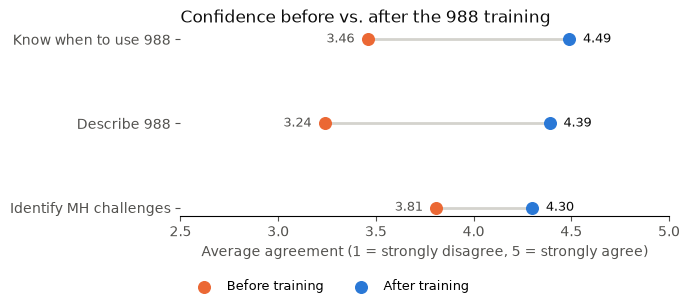

In [ ]:
BLUE, ORANGE = "#2a78d6", "#eb6834"      # validated categorical slots 1 and 2
INK, MUTED = "#0b0b0b", "#52514e"

fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(overall))
ax.hlines(y, overall["before (avg 1-5)"], overall["after (avg 1-5)"], color="#d4d3cd", lw=2)
ax.scatter(overall["before (avg 1-5)"], y, s=70, color=ORANGE, label="Before training", zorder=3)
ax.scatter(overall["after (avg 1-5)"], y, s=70, color=BLUE, label="After training", zorder=3)
for i, (b, f) in enumerate(zip(overall["before (avg 1-5)"], overall["after (avg 1-5)"])):
    ax.text(f + 0.07, i, f"{f:.2f}", va="center", color=INK, fontsize=9)
    ax.text(b - 0.07, i, f"{b:.2f}", va="center", ha="right", color=MUTED, fontsize=9)
ax.set_yticks(y, overall.index)
ax.set_xlim(2.5, 5)
ax.set_xlabel("Average agreement (1 = strongly disagree, 5 = strongly agree)", color=MUTED)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.28), ncol=2, fontsize=9)
ax.set_title("Confidence before vs. after the 988 training", loc="left", color=INK)
plt.tight_layout(); plt.show()

## 2.2 Gaps by community (first pass)

`summarize(group_col)` builds one comparison table for any grouping column. For each group it reports the size (`n`), the before/after averages, the gain, the share who ended up confident on all 3, the share who got worse, the share at the ceiling, and the Net Promoter Score (`% promoters - % detractors`).

Following the completeness rule, each measure only uses rows that answered that question, and `n_aspects` / `n_recommend` / `n_likely_call` show how many rows each one is based on. Groups with fewer than 20 rows are marked `small_n`, so we don't over-read them.

In [ ]:
def nps(scores):
    '''Net Promoter Score (-100 to +100) from 0-10 scores, ignoring blanks.
    Promoters are 9-10, detractors 0-6.
    Usage: nps(a["recommend_0_10"])  ->  e.g. 12.5'''
    s = scores.dropna()          # skipped answers must not count as "not a promoter"
    if s.empty:
        return np.nan
    return ((s >= 9).mean() - (s <= 6).mean()) * 100

def summarize(data, group_col, min_n=20):
    '''One row per group with outcome metrics; marks groups under min_n.
    Completeness rule: each metric only uses rows that answered that question,
    and the n_* columns say how many rows each metric is based on.
    Usage: summarize(a, "county")'''
    g = data.groupby(group_col, observed=True)
    out = pd.DataFrame({
        "n": g.size(),
        "pre_avg": g["pre_avg"].mean(),
        "post_avg": g["post_avg"].mean(),
        "gain_avg": g["gain_avg"].mean(),
        "pct_confident_post": g["confident_post"].mean() * 100,
        "pct_went_down": g["went_down"].mean() * 100,
        "pct_ceiling_pre": g["ceiling_pre"].mean() * 100,
        "n_aspects": g["aspects_avg"].count(),           # .count() = number of non-blank answers
        "aspects_avg": g["aspects_avg"].mean(),          # .mean() skips blanks automatically
        "n_recommend": g["recommend_0_10"].count(),
        "nps": g["recommend_0_10"].apply(nps),
        "n_likely_call": g["likely_call_0_10"].count(),
        "likely_call_avg": g["likely_call_0_10"].mean(),
    }).round(2)
    out["small_n"] = out["n"] < min_n
    return out.sort_values("n", ascending=False)

summarize(a, "county")

,n,pre_avg,post_avg,gain_avg,pct_confident_post,pct_went_down,pct_ceiling_pre,n_aspects,aspects_avg,n_recommend,nps,n_likely_call,likely_call_avg,small_n
county,,,,,,,,,,,,,,
Anne Arundel,926,3.59,4.38,0.79,85.31,4.97,6.59,790,4.39,912,-5.81,122,7.11,False
Prince George's,298,3.30,4.42,1.12,85.57,4.70,8.05,286,4.52,280,55.00,135,7.84,False
Montgomery,33,2.77,4.64,1.87,93.94,0.00,9.09,33,4.73,33,81.82,22,9.55,False
Queen Anne's,12,3.50,4.17,0.67,91.67,0.00,25.00,11,4.48,11,0.00,11,7.18,True


In [ ]:
summarize(a, "role_primary")

,n,pre_avg,post_avg,gain_avg,pct_confident_post,pct_went_down,pct_ceiling_pre,n_aspects,aspects_avg,n_recommend,nps,n_likely_call,likely_call_avg,small_n
role_primary,,,,,,,,,,,,,,
Student,1068,3.53,4.35,0.82,83.90,5.52,5.81,921,4.37,1039,-2.69,251,7.35,False
Community member,80,3.15,4.60,1.46,96.25,0.00,13.75,79,4.72,79,79.75,23,9.48,False
School staff,57,3.64,4.70,1.06,96.49,0.00,12.28,57,4.74,56,80.36,2,10.00,False
Caregiver/parent,53,3.31,4.49,1.18,90.57,1.89,18.87,52,4.69,51,74.51,12,9.33,False
Multiple roles,11,3.45,4.67,1.21,100.00,0.00,9.09,11,4.70,11,90.91,2,10.00,True


In [ ]:
summarize(a, "spanish_speaker")

,n,pre_avg,post_avg,gain_avg,pct_confident_post,pct_went_down,pct_ceiling_pre,n_aspects,aspects_avg,n_recommend,nps,n_likely_call,likely_call_avg,small_n
spanish_speaker,,,,,,,,,,,,,,
False,1203,3.50,4.39,0.89,85.79,4.90,6.40,1055,4.42,1171,7.86,279,7.66,False
True,66,3.49,4.49,0.99,83.33,1.52,21.21,65,4.64,65,55.38,11,7.18,False


### Students vs. adults, within each county

Most rows are students, and most students are in Anne Arundel / Prince George's. Splitting by both at once (`[county, is_student]`) shows whether a county difference is really an age/role difference.

In [ ]:
summarize(a, ["county", "is_student"])

n  pre_avg  post_avg  gain_avg  pct_confident_post  pct_went_down  pct_ceiling_pre  n_aspects  aspects_avg  n_recommend    nps  n_likely_call  likely_call_avg  small_n
county          is_student                                                                                                                                                                           
Anne Arundel    True        880     3.59      4.37      0.78               84.66           5.23             6.25        744         4.36          866 -10.16            118             7.03    False
Prince George's True        181     3.24      4.29      1.05               79.56           7.18             2.76        170         4.40          166  37.95            124             7.72    False
                False       117     3.39      4.62      1.23               94.87           0.85            16.24        116         4.70          114  79.82             11             9.27    False
Anne Arundel    False        46     3.70      4.65      0.95               97.83           0.00            13.04         46         4.76           46  76.09              4             9.75    False
Montgomery      False        30     2.63      4.62      1.99               93.33           0.00             6.67         30         4.70           30  86.67             19             9.79    False
Queen Anne's    False         6     3.00      3.72      0.72               83.33           0.00            16.67          5         4.80            5  40.00              5             8.60     True
                True          6     4.00      4.61      0.61              100.00           0.00            33.33          6         4.22            6 -33.33              6             6.00     True
Montgomery      True          3     4.11      4.78      0.67              100.00           0.00            33.33          3         5.00            3  33.33              3             8.00     True

## 2.3 Did the key message land? Coding the "most valuable thing" answers

The training's main goal is that people learn **you don't have to be in a crisis to call 988**. We can check that from the open-ended answers. Below is a simple keyword-based theme coder (regular expressions). Each theme becomes a True/False column. This is a **first draft**: the patterns should be reviewed by reading a sample of rows (shown at the end).

| Theme | Example phrases it catches |
|---|---|
| `theme_no_crisis_needed` | "don't have to be in a crisis", "not just for suicide", "anyone can call", "bad day", "any time" |
| `theme_call_for_others` | "for a friend", "for someone else", "family" |
| `theme_text_chat` | "text", "chat" |
| `theme_free_confidential` | "free", "confidential", "anonymous" |
| `theme_vs_911` | "911", "police" |
| `theme_how_it_works` | "what happens when you call", "trained counselors", "local", "de-escalate", "safety plan" |

In [ ]:
THEMES = {
    "theme_no_crisis_needed": r"(n[o']t|never|don'?t|do not|doesn'?t|isn'?t|without)\b.{0,25}\b(crisis|emergenc|suicid)"
                              r"|not (just|only)|any ?one can|any ?time|bad day|for (anything|everything|everyone)"
                              r"|no (reason|problem) (is )?too small|no matter (what|how)|cualquier",
    "theme_call_for_others":  r"\b(friend|someone else|others?\b|family|loved one|another person|somebody|peer|famil|amig|hij)",
    "theme_text_chat":        r"\b(text|chat|mensaje)",
    "theme_free_confidential":r"\b(free|confidential|anonymous|privat|gratis|confidencial)",
    "theme_vs_911":           r"911|police|cops",
    "theme_how_it_works":     r"what happens|how it works|counselor|local|de-?escalat|safety plan|trained|listen",
}
txt = a["most_valuable_text"].fillna("").str.lower()
for col, pat in THEMES.items():
    a[col] = txt.str.contains(pat.replace("(", "(?:").replace("(?:?:", "(?:"), regex=True)   # (?:...) = group without capturing
a["n_themes"] = a[list(THEMES)].sum(axis=1)

(a.loc[~a["flag_low_effort_text"], list(THEMES)].mean() * 100).round(1).sort_values(ascending=False).to_frame("% of answers with text")

,% of answers with text
theme_no_crisis_needed,15.2
theme_call_for_others,4.6
theme_vs_911,3.0
theme_text_chat,2.3
theme_how_it_works,2.1
theme_free_confidential,1.2


In [ ]:
theme_by = (a[~a["flag_low_effort_text"]]
            .groupby("role_primary")[["theme_no_crisis_needed", "theme_call_for_others", "theme_text_chat", "theme_vs_911"]]
            .mean().mul(100).round(1))
theme_by.insert(0, "n_with_text", a[~a["flag_low_effort_text"]].groupby("role_primary").size())
theme_by

,n_with_text,theme_no_crisis_needed,theme_call_for_others,theme_text_chat,theme_vs_911
role_primary,,,,,
Caregiver/parent,44,4.5,4.5,2.3,6.8
Community member,66,7.6,3.0,4.5,15.2
Multiple roles,10,20.0,10.0,10.0,20.0
School staff,46,6.5,6.5,0.0,4.3
Student,874,16.7,4.6,2.2,1.6


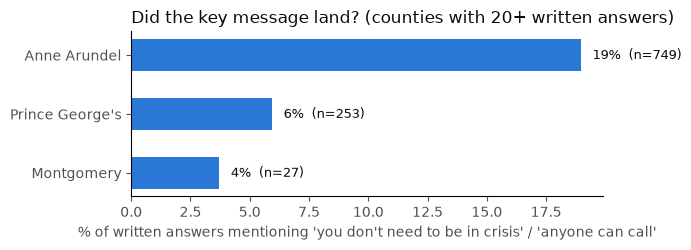

In [ ]:
s = (a[~a["flag_low_effort_text"]].groupby("county")["theme_no_crisis_needed"]
       .agg(["mean", "size"]).query("size >= 20").sort_values("mean"))

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(s.index, s["mean"] * 100, color=BLUE, height=0.55)
for i, (v, n) in enumerate(zip(s["mean"] * 100, s["size"])):
    ax.text(v + 0.5, i, f"{v:.0f}%  (n={n})", va="center", color=INK, fontsize=9)
ax.set_xlabel("% of written answers mentioning 'you don't need to be in crisis' / 'anyone can call'", color=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
ax.set_title("Did the key message land? (counties with 20+ written answers)", loc="left", color=INK)
plt.tight_layout(); plt.show()

Spot-check the theme coder: a random sample of answers with their themes. If the coder misses or mis-tags things, we adjust the patterns above.

In [ ]:
a.loc[~a["flag_low_effort_text"], ["most_valuable_text"] + list(THEMES)].sample(15, random_state=7)

,most_valuable_text,theme_no_crisis_needed,theme_call_for_others,theme_text_chat,theme_free_confidential,theme_vs_911,theme_how_it_works
11,This is a valuable tool to add to my toolkit. Also love that they have a Spa...,False,False,False,False,False,False
366,you can call 988 for anything (mostly),True,False,False,False,False,False
844,My call/text is anonymous,False,False,True,True,False,False
141,How to prevent suicidale incidents from happening.,False,False,False,False,False,False
836,988 answers in 30 seconds,False,False,False,False,False,False
807,That you don't only have to call for thoughts of suicide,False,False,False,False,False,False
225,About how it worked,False,False,False,False,False,False
796,that it's confidential,False,False,False,True,False,False
722,How they work,False,False,False,False,False,False
393,"You can use 988 at any time, for whatever problem you have",True,False,False,False,False,False


## 2.4 First observations (leads to check, not conclusions)

1. **The training works on average.** Average confidence goes from about 3.5 to 4.4 (out of 5). The biggest jump is on *"I can describe 988 and how it works"* (67% of people improved).
2. **Students are the biggest gap on enthusiasm and intent.** Adults (staff, parents, community members) have NPS around +70 to +80. Students are around 0, and Anne Arundel students specifically are about -10, compared with about +38 for Prince George's students. Students also report lower likelihood to call 988 (~7.4/10 vs ~9.3+/10 for adults, on rows that were asked).
3. **Spanish speakers (66 rows) do about as well as everyone else, once bad rows are removed.** About 83% are confident on all 3 statements after training vs about 86% for everyone else. An earlier version of this analysis showed a bigger gap (78% vs 85%), but that was mostly caused by likely reversed-scale answers, which section 1.16 removes. Many more of them were already at the top of the scale before (21% vs 6%), which can hide real learning, and they rate the training higher (NPS about +55 vs +8). At least one Spanish answer says 988 is *only* for very serious situations, the exact opposite of the key message.
4. **The key message is rarely written back.** Only ~15% of written answers mention "you don't need to be in a crisis / anyone can call", and it is even lower for adults (~4 to 7%) than for students (~17%). By county it is ~19% in Anne Arundel but only ~6% in Prince George's and ~4% in Montgomery. Part of that is the keyword coder (it is English-heavy, and Prince George's has most of the Spanish answers), so this needs a manual check before we trust it.
5. **Reach is very uneven.** 73% of responses are from Anne Arundel and 23% from Prince George's. Montgomery County, where EveryMind is the local 988 center, has only 33 responses, and Queen Anne's has 12.
6. **Survey version changes are a data gap in themselves.** The "likely to call" question was only on ~23% of forms, so intent can only be compared on ~290 people.

## 2.5 Recommendations for the advanced cleaning phase (to discuss)

### A. Decisions the team needs to make
1. ~~Completeness rule.~~ **Decided:** `complete_core` + per-question bases (see section 1.13). Likely-to-call is only analyzed where `asked_likely_call` is True.
2. **Out-of-area rows** (Fairfax VA, Harris TX): drop, or keep as their own group? Currently dropped from `analysis_ready` and the clean sheet.
3. **`Very agree` / `Satisfied` mapping.** Keep the mapping, or treat those as missing?
4. **Speed threshold.** 20 seconds is a guess. Look at the distribution of `seconds_taken` and pick a cutoff together.
5. **Retrospective pre-test caveat.** "Before" answers were given *after* the training, from memory. That is a standard method, but it tends to inflate gains a little. Worth stating in the final write-up.

### B. New columns to build
| Column | How | Why it helps the "gaps" question |
|---|---|---|
| `session_id` | combine `county` + `training_date` | compare individual sessions/schools/presenters; many gaps are session-level, not community-level |
| `session_size` | count rows per `session_id` | small sessions vs. big assemblies may work differently |
| `county_pct_black`, `county_pct_hispanic`, `county_median_income`, `county_pct_under_18` | join from Census ACS 5-year tables by county | the only way to bring in "communities of color" with the current survey, at the **community** level (not individual) |
| `school_id` / school demographics | if EveryMind knows which school each session was at, join MSDE school-level data (% FARMS, race/ethnicity) | much finer-grained than county; strongest proxy available |
| `season` / `school_term` | from `training_date` | fall vs. spring cohorts; question set changed between them |
| `form_version` | infer from which questions are present (e.g. `asked_likely_call`, aspects present) | so we never compare answers across different versions of the survey by accident |
| theme columns (2.3) | refine the regex, or hand-code ~200 answers and check agreement | measures the **key message**, not just confidence |
| `improve_theme_*` | same approach on `improve_text` (e.g. "more interactive", "longer", "food", "nothing") | tells us *what to change* for groups with gaps |
| `asked_question_text` | many "improve" answers are actually questions ("how many people call a day?") | separate feedback from curiosity; questions show what people still don't understand |
| `translated_text` | translate Spanish answers to English (Google Translate API or by hand, only ~20 rows) | so Spanish answers are included in the theme coding |

### C. Ways to group for the gaps analysis
* **Reach** (are we reaching the target audience?): count of responses by `county`, `role_primary`, `spanish_speaker`, and by month. Compare to the population of each county (Census) to get a "reach rate". Right now Montgomery County, where EveryMind is based, has very few responses (~30), which is itself a gap worth raising.
* **Effectiveness** (does it work for them?): `gain_avg`, `pct_confident_post`, `pct_went_down`, by group. Always control for `pct_ceiling_pre` (groups that already knew 988 will show smaller gains).
* **Key message** (did "you don't need to be in crisis" land?): `theme_no_crisis_needed` by group.
* **Intent** (would they actually call?): `likely_call_0_10` by group, only on `asked_likely_call` rows.
* **Experience**: `presenter_engaged`, `well_organized`, `nps` by group. Low ratings in one group may explain low gains.

### D. Suggested additions to the survey itself (for future rounds)
* Optional **age range**, **race/ethnicity**, **grade** (for students), and **home language** questions. Without these, "communities of color" can only be estimated at county or school level.
* A direct question on the key message, e.g. *"True or false: you should only contact 988 if you are in a crisis."* That gives a clean yes/no measure instead of relying on text coding.
* Keep the question set **the same** across all sessions (the missing "likely to call" question cost us ~1,000 rows of data).

---
# Part 3: Deeper Insights (the angles averages hide)

**The question we are answering (from the case brief):**
> How can EveryMind use its 988 training feedback data to develop an actionable solution for evaluating training effectiveness, identifying gaps across communities, and continuously improving future trainings?

The brief breaks that into four jobs: **evaluate effectiveness**, find **knowledge and behavioral-intent gaps**, compare **participant groups**, and make **recommendations**. At the kickoff EveryMind added what they care about most: reaching **younger people** and **communities of color**, and landing one key message, *you do not have to be in a crisis to contact 988*.

Part 2 gave the standard picture (average gain, NPS by group). Each section below looks for something those averages hide, and ends with the decision it supports. All of this uses `a` (the analysis-ready rows with the Part 2 columns).

## 3.1 Students learn the content but do not like the format

Two questions measure different things. The 3 knowledge statements measure **what people learned**. The 0 to 10 recommend score measures **how they felt about the session**. If both are low, the content is not landing. If knowledge is high but recommend is low, people learned it and still did not enjoy it, which points at **delivery**, not content.

We split everyone into four boxes: confident after training (all 3 statements 4 or 5) or not, and would recommend (7 to 10) or not (0 to 6).

In [ ]:
def learn_vs_like(data):
    """Percent of rows in each learned/liked box, one row per group.
    Learned = all 3 post statements are 4+. Liked = recommend score 7+.
    Usage: learn_vs_like(a[a["is_student"]])"""
    d = data.dropna(subset=["recommend_0_10"])
    learned = d["confident_post"]
    liked = d["recommend_0_10"] >= 7
    return pd.Series({
        "n": len(d),
        "learned + liked": (learned & liked).mean() * 100,
        "learned, did NOT like": (learned & ~liked).mean() * 100,
        "did not learn, liked": (~learned & liked).mean() * 100,
        "did not learn, did not like": (~learned & ~liked).mean() * 100,
    }).round(1)

box = pd.DataFrame({"Students": learn_vs_like(a[a["is_student"]]),
                    "Adults": learn_vs_like(a[~a["is_student"]])}).T
box

,n,learned + liked,"learned, did NOT like","did not learn, liked","did not learn, did not like"
Students,1041.0,58.2,26.3,7.2,8.3
Adults,195.0,92.8,2.6,4.6,0.0


**Read it like this:** look at the *"learned, did NOT like"* column. For students it is about one in four, for adults it is small. Those students got the message and still would not recommend the session. That is a format problem (length, interactivity, a lecture in an assembly), and it is fixable without rewriting the content. The "improve" comments in 2.5 (themes like *more interactive*, *videos*, *shorter*) are the place to look for what to change.

## 3.2 Scores are falling because the audience changed, not the training

If you plot the recommend score by month it drops sharply in the second half of the year. The obvious reading is "the training got worse". Before saying that, check **who** was trained each month. If the mix moved from adults to students, the overall average falls even if every group scores the same as before (this is called *Simpson's paradox*).

In [ ]:
monthly = (a.assign(month=a["training_date"].dt.to_period("M"))
             .groupby("month")
             .agg(n=("row_id", "size"),
                  pct_students=("is_student", lambda s: round(s.mean() * 100)),
                  recommend_all=("recommend_0_10", "mean"),
                  recommend_students=("recommend_0_10", lambda s: s[a.loc[s.index, "is_student"]].mean()),
                  recommend_adults=("recommend_0_10", lambda s: s[~a.loc[s.index, "is_student"]].mean()))
             .round(2))
monthly

,n,pct_students,recommend_all,recommend_students,recommend_adults
month,,,,,
2025-10,25,0,9.40,NaN,9.40
2025-11,1,0,10.00,NaN,10.00
2025-12,32,3,9.19,10.00,9.16
2026-01,38,3,9.32,10.00,9.31
2026-02,9,0,8.89,NaN,8.89
2026-03,29,55,9.52,9.09,9.92
2026-04,287,82,7.37,6.92,9.35
2026-05,171,93,8.18,8.09,9.33
2026-06,27,96,6.88,6.76,10.00


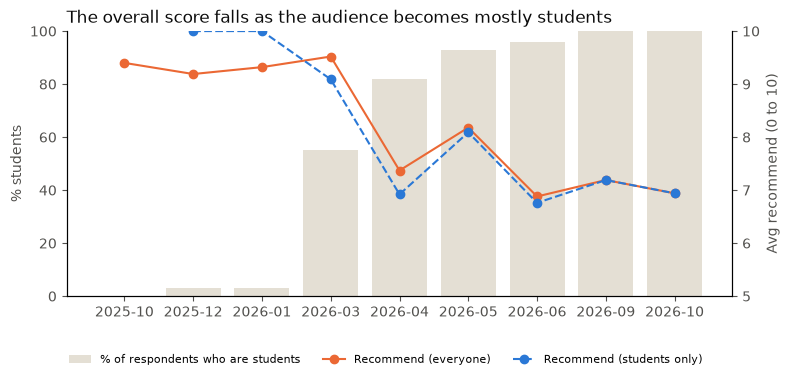

In [ ]:
m = monthly[monthly["n"] >= 20]          # skip tiny months, their averages jump around
fig, ax1 = plt.subplots(figsize=(8, 3.4))
ax1.bar(m.index.astype(str), m["pct_students"], color="#e4dfd4", label="% of respondents who are students")
ax1.set_ylabel("% students", color=MUTED)
ax1.set_ylim(0, 100)
ax2 = ax1.twinx()
ax2.plot(m.index.astype(str), m["recommend_all"], color=ORANGE, marker="o", label="Recommend (everyone)")
ax2.plot(m.index.astype(str), m["recommend_students"], color=BLUE, marker="o", ls="--", label="Recommend (students only)")
ax2.set_ylim(5, 10)
ax2.set_ylabel("Avg recommend (0 to 10)", color=MUTED)
for ax in (ax1, ax2):
    ax.spines[["top"]].set_visible(False)
    ax.tick_params(colors=MUTED)
fig.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.08, -0.12), ncol=3, fontsize=8)
ax1.set_title("The overall score falls as the audience becomes mostly students", loc="left", color=INK)
plt.tight_layout(); plt.show()

**Read it like this:** the orange line (everyone) drops as the grey bars (share of students) rise. Adults score about 9.2 to 10 in every month, and students sit around 7 in almost every month from April on. Neither group is getting steadily worse, so most of the drop is **who** is in the room, not a decline in quality. This matters for how EveryMind reports results: a single overall NPS per month would wrongly look like the program is getting worse. **Always report students and adults separately.**

## 3.3 Same audience, very different sessions: delivery matters

Comparing counties mixes up many things (different schools, different presenters, different audiences). A cleaner test: keep the audience fixed (**students only**) and compare **sessions** (one training date in one county). If sessions with the same kind of audience get very different scores, something about the session itself (presenter, room, length, format) is driving it.

Only sessions with at least 10 student responses are kept, so one or two people cannot swing a result.

In [ ]:
a["session_id"] = a["training_date"].dt.strftime("%Y-%m-%d") + " | " + a["county"]

stud_sessions = (a[a["is_student"]]
                 .groupby("session_id")
                 .agg(n=("row_id", "size"),
                      gain_avg=("gain_avg", "mean"),
                      recommend_avg=("recommend_0_10", "mean"),
                      nps=("recommend_0_10", nps),
                      pct_learned_not_liked=("confident_post", lambda s: ((s) & (a.loc[s.index, "recommend_0_10"] <= 6)).mean() * 100))
                 .query("n >= 10")
                 .round(2)
                 .sort_values("recommend_avg"))
print(len(stud_sessions), "student sessions with 10+ responses")
print("recommend range:", stud_sessions["recommend_avg"].min(), "to", stud_sessions["recommend_avg"].max())
stud_sessions

19 student sessions with 10+ responses
recommend range: 4.83 to 9.09


,n,gain_avg,recommend_avg,nps,pct_learned_not_liked
session_id,,,,,
2026-04-14 | Anne Arundel,31,0.87,4.83,-68.97,61.29
2026-10-08 | Anne Arundel,73,0.76,6.33,-31.51,36.99
2026-04-15 | Anne Arundel,30,1.33,6.50,-23.33,36.67
2026-06-01 | Prince George's,26,0.12,6.76,-12.00,7.69
2026-10-21 | Anne Arundel,57,0.57,6.77,-15.79,28.07
2026-04-28 | Anne Arundel,38,0.91,6.78,-27.78,31.58
2026-10-09 | Anne Arundel,48,0.51,6.79,-16.67,20.83
2026-09-28 | Anne Arundel,143,0.94,6.86,-18.88,34.27
2026-05-01 | Anne Arundel,52,0.75,7.12,-8.33,26.92


**Read it like this:** the top and bottom rows are the same kind of audience (students) with very different results. The best sessions are a ready-made playbook: EveryMind can find out what those presenters or schools did differently and copy it. The worst sessions are where to send coaching first. This is also the strongest argument for recording **presenter** and **school** on the survey form, so this comparison becomes routine.

## 3.4 The average gain hides the real impact

Everyone rated themselves *before* and *after*. If someone already picked 5 ("strongly agree") before, they **cannot** go up. Averaging those people in with everyone else makes the training look weaker than it is. Split people by whether they had room to grow (at least one "before" answer under 4).

In [ ]:
pre_cols = [f"pre_{it}_num" for it in ITEMS]
a["had_room_to_grow"] = (a[pre_cols] < 4).any(axis=1)

room = (a.groupby("had_room_to_grow")
          .agg(n=("row_id", "size"), avg_gain=("gain_avg", "mean"),
               pct_confident_after=("confident_post", "mean"))
          .rename(index={True: "Had room to grow", False: "Already confident before"}))
room["pct_of_people"] = (room["n"] / room["n"].sum() * 100).round(1)
room["pct_confident_after"] = (room["pct_confident_after"] * 100).round(1)
room.round(2)

,n,avg_gain,pct_confident_after,pct_of_people
had_room_to_grow,,,,
Already confident before,419,0.25,94.5,33.0
Had room to grow,850,1.21,81.3,67.0


**Read it like this:** for the people the training is actually for (those not already confident), the gain is several times bigger than the headline average. EveryMind should report this number. It also suggests a small fix to the survey: the already-confident group tells us little about learning, so a harder knowledge check (for example a true/false question like *"You can contact 988 even if you are not in a crisis"*) would measure learning better than self-rating.

## 3.5 Behavioral intent: the biggest gap is where 988 is used most

Confidence is not the goal; **contacting 988 when needed** is. The closest thing the survey has is *"How likely are you to call 988?"* (0 to 10). It was only on some versions of the form, so we only use rows that were asked (`asked_likely_call`).

In [ ]:
intent = (a[a["asked_likely_call"]]
            .groupby("role_primary")
            .agg(n=("row_id", "size"),
                 likely_call_avg=("likely_call_0_10", "mean"),
                 pct_9_or_10=("likely_call_0_10", lambda s: (s >= 9).mean() * 100),
                 pct_6_or_below=("likely_call_0_10", lambda s: (s <= 6).mean() * 100))
            .round(1)
            .sort_values("n", ascending=False))
intent

,n,likely_call_avg,pct_9_or_10,pct_6_or_below
role_primary,,,,
Student,251,7.4,41.0,31.1
Community member,23,9.5,82.6,0.0
Caregiver/parent,12,9.3,83.3,8.3
Multiple roles,2,10.0,100.0,0.0
School staff,2,10.0,100.0,0.0


**Read it like this:** students are clearly less likely to say they would call than adults (7.4 vs about 9.5, and 31% of students answer 6 or lower). Only about 40 adults were asked, so the adult figure is rough, but the student figure is based on 251 people. Part 4 adds why that matters: EveryMind told us its **highest text and chat volume comes from ages 13 to 17**. The group least ready to reach out after the training is the group that uses 988 the most. Two practical points follow:
* Students may prefer **text or chat** over a phone call, and the question only asks about *calling*. The form should ask *"call, text, or chat"*, otherwise we may be under-measuring student intent.
* The question should be on **every** version of the form. Right now intent can only be judged for about 290 people.

---
# Part 4: Outside Data ("compared to what?" and "who is missing?")

The survey only describes people who attended. Outside data adds three things it cannot give on its own:
1. **A benchmark**, so a score means something.
2. **Who is missing**, by comparing who attended to who lives in each county.
3. **Where need is highest**, so gaps can be ranked.

Rules we follow so this stays honest:
* Outside data is **county level only**. It never tells us anything about an individual respondent.
* There are only 4 Maryland counties in the clean data, so these comparisons are **descriptive**, not statistical tests.
* Every number below has its source written next to it.

## 4.1 Benchmark: EveryMind's own 988 figures

These were presented by EveryMind at the Buildfest kickoff (Chief Program Officer, case overview), so they are the partner's own numbers:

| Figure | Value | Use in our analysis |
|---|---|---|
| Americans who have **heard of** 988 | 74% | baseline awareness |
| Americans who **know what 988 is** | 28% | national benchmark for our "can describe 988" item |
| Americans who **use** 988 | under 20% | the behavior gap the training is meant to close |
| Contacts EveryMind answered last year | about 65,000 | scale of the service |
| Contacts de-escalated without emergency services | 98.5% | supports the message that 988 is not "calling the police" |
| Age group with highest text and chat volume | 13 to 17 | ranks the student gap as the highest priority |

Below we put our post-training result next to the national 28%.

In [ ]:
NATIONAL_KNOW_WHAT_988_IS = 28    # % of Americans familiar with what 988 is (EveryMind, Buildfest kickoff)

bench = pd.DataFrame({
    "Group": ["US adults (national)", "Our respondents, before (self-rated)", "Our respondents, after"],
    "% who can describe 988": [NATIONAL_KNOW_WHAT_988_IS,
                               round((a["pre_describe_num"] >= 4).mean() * 100),
                               round((a["post_describe_num"] >= 4).mean() * 100)],
})
bench

,Group,% who can describe 988
0,US adults (national),28
1,"Our respondents, before (self-rated)",47
2,"Our respondents, after",92


**Read it like this:** the national figure and our survey item are not the exact same question (one is a national poll, ours is a self-rating), so treat this as context, not a precise comparison. Still, it shows the training takes people from roughly the national level of understanding to almost everyone saying they can describe 988.

## 4.2 Who is missing: survey respondents vs. county population

**Source:** U.S. Census Bureau, American Community Survey 2024 5-year estimates (2020 to 2024), tables B03002 (Hispanic or Latino origin by race), C16001 (language spoken at home) and B09001 (population under 18 by age). Pulled through Census Reporter (censusreporter.org), which serves the same ACS tables without an API key, and saved to `data/acs_2024_5yr_md_counties.csv` so the notebook runs offline.

The survey does **not** ask about race, ethnicity or age, so we cannot measure "communities of color" directly. What we *can* do is compare each county's population with what we see in that county's responses:
* Spanish at home (county) vs. share of respondents who answered in Spanish (form or text).
* Youth aged 12 to 17 (county) vs. number of students trained.

In [ ]:
acs = pd.read_csv("data/acs_2024_5yr_md_counties.csv")

def reach_table(data, census):
    """Join survey reach per county to Census county figures.
    Usage: reach_table(a, acs)  ->  one row per Maryland county"""
    s = (data.groupby("county")
             .agg(responses=("row_id", "size"),
                  students_trained=("is_student", "sum"),
                  pct_respondents_spanish=("spanish_speaker", lambda x: round(x.mean() * 100, 1)))
             .reset_index())
    t = census.merge(s, on="county", how="left").fillna({"responses": 0, "students_trained": 0})
    t["students_trained_per_1000_youth"] = (t["students_trained"] / t["youth_12_17"] * 1000).round(1)
    t["spanish_gap_pts"] = (t["pct_spanish_at_home"] - t["pct_respondents_spanish"]).round(1)
    return t[["county", "population", "responses", "pct_people_of_color", "pct_black", "pct_hispanic",
              "pct_spanish_at_home", "pct_respondents_spanish", "spanish_gap_pts",
              "youth_12_17", "students_trained", "students_trained_per_1000_youth"]]

reach = reach_table(a, acs)
reach

,county,population,responses,pct_people_of_color,pct_black,pct_hispanic,pct_spanish_at_home,pct_respondents_spanish,spanish_gap_pts,youth_12_17,students_trained,students_trained_per_1000_youth
0,Anne Arundel,598166,926,38.3,17.6,10.5,6.9,0.1,6.8,46568,880,18.9
1,Montgomery,1065949,33,60.5,18.3,21.0,17.7,0.0,17.7,86988,3,0.0
2,Prince George's,959754,298,89.2,58.2,22.5,19.5,17.8,1.7,69623,181,2.6
3,Queen Anne's,51825,12,17.5,5.5,5.7,3.7,100.0,-96.3,4188,6,1.4


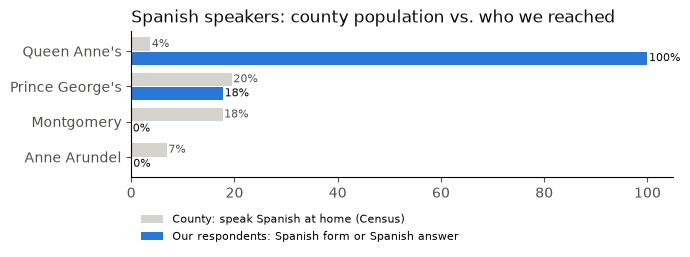

In [ ]:
fig, ax = plt.subplots(figsize=(7, 2.8))
y = np.arange(len(reach))
ax.barh(y + 0.2, reach["pct_spanish_at_home"], height=0.38, color="#d4d3cd", label="County: speak Spanish at home (Census)")
ax.barh(y - 0.2, reach["pct_respondents_spanish"], height=0.38, color=BLUE, label="Our respondents: Spanish form or Spanish answer")
for i, (c, r) in enumerate(zip(reach["pct_spanish_at_home"], reach["pct_respondents_spanish"])):
    ax.text(c + 0.3, i + 0.2, f"{c:.0f}%", va="center", fontsize=8, color=MUTED)
    ax.text(r + 0.3, i - 0.2, f"{r:.0f}%", va="center", fontsize=8, color=INK)
ax.set_yticks(y, reach["county"])
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.18), ncol=1, fontsize=8)
ax.set_title("Spanish speakers: county population vs. who we reached", loc="left", color=INK)
plt.tight_layout(); plt.show()

**Read it like this:**
* **Montgomery is almost missing.** It is EveryMind's home county and its own 988 call center area, it has the largest population, and about 61% of residents are people of color. Yet it has only 33 responses and 3 students trained. This is the single biggest reach gap in the data.
* **Spanish speakers.** Prince George's is well matched (about 18% of respondents answered in Spanish, close to the 19.5% of residents who speak Spanish at home). Anne Arundel, where most trainings happen, is not: about 7% of residents speak Spanish at home but almost no respondents answered in Spanish. Queen Anne's shows 100% because its only 12 responses came from one Spanish-language session, so ignore that bar. Caveat: our "Spanish" measure only catches people who chose the Spanish form or wrote in Spanish, so bilingual people who answered in English are missed.
* **Youth reach.** `students_trained_per_1000_youth` is about 19 per 1,000 teens in Anne Arundel, but under 3 in Prince George's and 0 in Montgomery. The two most diverse counties have the lowest youth reach, which is exactly where EveryMind said it wants to grow. Caveat: some "students" may be college students, and youth counts are ages 12 to 17, so this is an approximation.
* **Communities of color.** Prince George's is about 89% people of color and Montgomery about 61%. Reach in those two counties is the best available proxy for reaching communities of color until the survey asks directly.

## 4.3 Next outside sources (not pulled yet)

| Source | What it adds | How to use it |
|---|---|---|
| SAMHSA / 988 Lifeline monthly Maryland data | actual 988 contacts over time | check whether contacts rise after heavy training months (a pattern, not proof) |
| Maryland Youth Risk Behavior Survey (Maryland Department of Health) | student mental-health need by county | rank counties by need, so youth gaps in high-need counties come first |
| Maryland State Department of Education enrollment | students per county and school | a precise denominator for "share of students reached" |
| CDC WONDER | suicide rates by county | context on need; small counties have suppressed or unstable numbers |

---
# Part 5: What This Means for EveryMind (draft recommendations)

Each recommendation comes from a finding above, so it can be checked.

| # | Finding | Recommendation | How EveryMind would know it worked |
|---|---|---|---|
| 1 | Students learn the content but many would not recommend it (3.1) | Make a student version: shorter, more interactive, more real examples; test it in a few schools | "learned, did not like" share for students falls |
| 2 | Overall scores fall because the audience shifted to students (3.2) | Always report students and adults separately; never one combined monthly NPS | Reports stop showing false "declines" |
| 3 | Same-audience sessions differ hugely (3.3) | Add presenter and school to the form; study the top sessions and share what they do | Gap between best and worst sessions narrows |
| 4 | Averages hide impact for people who needed it (3.4) | Report gain for "had room to grow"; add one true/false knowledge question | A measure of learning that is not capped at 5 |
| 5 | Students are least likely to reach out, and 13 to 17 year olds use 988 most (3.5, 4.1) | Ask "call, text, or chat" on every form; teach text and chat explicitly in student sessions | Student intent rises and can be measured on every response |
| 6 | Montgomery (home county, 61% people of color) is almost untrained, and youth reach is lowest in the two most diverse counties (4.2) | Set a youth reach target per county (trained per 1,000 teens) and prioritize Montgomery and Prince George's schools | Trained-per-1,000-youth rises in those counties |
| 6b | Anne Arundel has almost no Spanish-language participation though about 7% speak Spanish at home (4.2) | Offer Spanish sessions there, using the Prince George's approach that already works; highlight *Press 2* | Spanish share of respondents moves toward the county share |
| 7 | The survey cannot measure communities of color (4.2) | Add optional age range, race/ethnicity and "how did you hear about this" questions | Gaps for communities of color become directly measurable |
| 8 | The key message is rarely written back (2.3) | Make "you don't need to be in a crisis" the session's closing line and ask about it directly on the form | % who agree with the key message, tracked each month |